# Train FRB CNN

Trains a CNN to classify CHIME/FRB-style dynamic-spectrum images as **burst** (label 1, from
`simulate_frbs_fitburst2.py`) vs **not a burst** (label 0, from `simulate_rfi.py`).

Expects two folders of `.npz` files, each with a `data_full` array (`num_freq x num_time`,
`num_freq` fixed at 256, `num_time` varies per-sample between 32 and 512) and a `metadata` dict.

```
project/
|-- sim_output2/      <- from simulate_frbs_fitburst2.py (label 1)
|-- sim_output_rfi/   <- from simulate_rfi.py             (label 0)
`-- train_frb_cnn.ipynb  <- this notebook
```

**Design choices** (carried over from the original script):
- Variable time length → every image is resized (linear interp) to a fixed `(FREQ_BINS, TIME_BINS)` grid.
- Per-image robust normalization (median/MAD), not a global scaler.
- Class balance is **not** assumed 50/50 — a `WeightedRandomSampler` + `pos_weight` handle imbalance.
- Split is done by file, stratified by label, with a fixed seed (no leakage).
- A final **Results** section at the end gives training curves, confusion matrix, ROC/PR curves,
  a classification report, and a grid of example predictions.

## 1. Imports

In [1]:
import json
import os
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

from sklearn.metrics import (confusion_matrix, roc_curve, auc, precision_recall_curve, average_precision_score, classification_report,)

## 2. Configuration

Everything that was a `--flag` in the original `argparse` CLI is just a variable here — edit and
re-run this cell instead of passing command-line args.

**Running on an Apple Silicon GPU (M1/M2/M3/M4):** these Macs don't have CUDA, but PyTorch can use
the on-chip GPU through the **MPS** (Metal Performance Shaders) backend. Requirements:
- macOS 12.3+
- `torch >= 1.12` installed as the normal (non-CUDA) build — `pip install torch --break-system-packages`
  is fine, there's no separate "Mac GPU" package
- Check it's available: `python3 -c "import torch; print(torch.backends.mps.is_available())"` should print `True`

Section 6 below auto-detects `cuda` → `mps` → `cpu`, in that order, so nothing else needs to change.

In [2]:
FREQ_BINS = 256   # matches NUM_FREQ in both simulators -- kept as a constant,
                   # not re-derived, so a mismatched file fails loudly
TIME_BINS = 256    # fixed resize target for the time axis (native range is 32-512)

FRB_DIR = "sim_output3"       # simulate_frbs_fitburst2.py output (label 1)
RFI_DIR = "sim_output_rfi1"    # simulate_rfi.py output (label 0)
OUTDIR = "runs/exp3"

EPOCHS = 25
BATCH_SIZE = 32
LR = 1e-3
WEIGHT_DECAY = 1e-4
VAL_FRAC = 0.15
TEST_FRAC = 0.15
SEED = 42
PATIENCE = 6           # early-stopping patience (epochs without val F1 improvement)
NUM_WORKERS = 0
FORCE_CPU = False      # set True to force CPU even if a GPU/MPS device is available

os.makedirs(OUTDIR, exist_ok=True)

## 3. Dataset

In [3]:
class DynSpecDataset(Dataset):
    """Loads .npz dynamic-spectrum files from an FRB dir (label 1) and an
    RFI dir (label 0), resizes each to (FREQ_BINS, TIME_BINS), and applies
    per-image robust normalization."""

    def __init__(self, files_labels):
        # files_labels: list of (path, label) tuples
        self.files_labels = files_labels

    def __len__(self):
        return len(self.files_labels)

    @staticmethod
    def _load_array(path: str) -> np.ndarray:
        npz = np.load(path, allow_pickle=True)
        arr = npz["data_full"].astype(np.float32)
        if arr.shape[0] != FREQ_BINS:
            raise ValueError(f"{path}: expected {FREQ_BINS} freq channels, got {arr.shape[0]}")
        return arr

    @staticmethod
    def _resize_time_axis(arr: np.ndarray, target_time: int) -> np.ndarray:
        """Linear interpolation along the time axis only (freq axis is
        already fixed at FREQ_BINS in both simulators)."""
        t_native = arr.shape[1]
        if t_native == target_time:
            return arr
        x_old = np.linspace(0.0, 1.0, t_native)
        x_new = np.linspace(0.0, 1.0, target_time)
        out = np.empty((arr.shape[0], target_time), dtype=np.float32)
        for i in range(arr.shape[0]):
            out[i] = np.interp(x_new, x_old, arr[i])
        return out

    @staticmethod
    def _robust_normalize(arr: np.ndarray) -> np.ndarray:
        """Per-image median/MAD normalization. Zeroed-out RFI-masked
        channels (exact zeros) are common to both classes by design, so
        they're excluded from the statistics to avoid biasing the scale."""
        nonzero = arr[arr != 0.0]
        if nonzero.size < 10:
            med, mad = 0.0, 1.0
        else:
            med = np.median(nonzero)
            mad = np.median(np.abs(nonzero - med)) + 1e-6
        return (arr - med) / (1.4826 * mad)

    def __getitem__(self, idx):
        path, label = self.files_labels[idx]
        arr = self._load_array(path)
        arr = self._resize_time_axis(arr, TIME_BINS)
        arr = self._robust_normalize(arr)
        arr = np.clip(arr, -8.0, 8.0)  # tame rare outlier pixels post-normalization
        # Last-resort safety net: a poisoned upstream file should never be
        # allowed to reach the model -- one NaN batch permanently NaNs
        # every weight via backprop. filter_finite_files() below already
        # removes these at dataset-build time; this just makes __getitem__
        # itself unable to emit a non-finite tensor even if that step was
        # skipped or a new bad file appears later.
        arr = np.nan_to_num(arr, nan=0.0, posinf=8.0, neginf=-8.0)
        tensor = torch.from_numpy(arr).unsqueeze(0)  # (1, F, T)
        return tensor, torch.tensor(label, dtype=torch.float32)

In [4]:
def filter_finite_files(files_labels, desc="scanning"):
    """Open every .npz up front and drop any whose data_full array
    contains NaN/Inf, BEFORE training starts. One non-finite image
    getting backpropagated through permanently NaNs every model weight
    (loss.backward() -> NaN gradient -> optimizer.step() writes NaN into
    every parameter -> every subsequent epoch is stuck predicting the same
    constant class, exactly the flat val P=0 R=0 F1=0 pattern). Cheap
    relative to a wasted 25-epoch training run."""
    clean, bad = [], []
    for path, label in files_labels:
        try:
            arr = np.load(path, allow_pickle=True)["data_full"]
        except Exception as e:
            bad.append((path, f"failed to load: {e}"))
            continue
        if not np.all(np.isfinite(arr)):
            bad.append((path, "contains NaN/Inf"))
            continue
        clean.append((path, label))

    print(f"[{desc}] {len(clean)} clean / {len(bad)} rejected out of {len(files_labels)} files")
    if bad:
        for path, reason in bad[:20]:
            print(f"  rejected: {path} ({reason})")
        if len(bad) > 20:
            print(f"  ... and {len(bad) - 20} more")
    return clean


def build_file_label_list(frb_dir: str, rfi_dir: str):
    frb_files = sorted(Path(frb_dir).glob("*.npz"))
    rfi_files = sorted(Path(rfi_dir).glob("*.npz"))
    if not frb_files:
        raise SystemExit(f"No .npz files found in --frb-dir {frb_dir}")
    if not rfi_files:
        raise SystemExit(f"No .npz files found in --rfi-dir {rfi_dir}")
    items = [(str(p), 1) for p in frb_files] + [(str(p), 0) for p in rfi_files]
    return items


def stratified_split(items, val_frac=0.15, test_frac=0.15, seed=42):
    rng = random.Random(seed)
    pos = [x for x in items if x[1] == 1]
    neg = [x for x in items if x[1] == 0]
    rng.shuffle(pos)
    rng.shuffle(neg)

    def split_one(lst):
        n = len(lst)
        n_val = int(round(n * val_frac))
        n_test = int(round(n * test_frac))
        test = lst[:n_test]
        val = lst[n_test:n_test + n_val]
        train = lst[n_test + n_val:]
        return train, val, test

    p_tr, p_va, p_te = split_one(pos)
    n_tr, n_va, n_te = split_one(neg)
    train = p_tr + n_tr
    val = p_va + n_va
    test = p_te + n_te
    rng.shuffle(train)
    rng.shuffle(val)
    rng.shuffle(test)
    return train, val, test

## 4. Model

In [5]:
class FRBCNN(nn.Module):
    """Small CNN, deliberately shallow: dynamic spectra here are 256x256
    single-channel images with a fairly simple discriminating structure
    (a bright, drifting/dispersed ridge vs banding/noise/RFI streaks), so a
    deep ImageNet-style net is unnecessary and more prone to overfitting on
    a few thousand simulated images."""

    def __init__(self, dropout=0.3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=5, padding=2), nn.BatchNorm2d(16), nn.ReLU(),
            nn.MaxPool2d(2),  # 256 -> 128

            nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d(2),  # 128 -> 64

            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2),  # 64 -> 32

            nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.AdaptiveAvgPool2d(4),  # -> 4x4, size-agnostic just in case
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 128), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(128, 1),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x).squeeze(1)  # raw logits

## 5. Train / eval loop

In [6]:
def run_epoch(model, loader, device, optimizer=None, pos_weight=None):
    is_train = optimizer is not None
    model.train(is_train)
    total_loss, all_logits, all_labels = 0.0, [], []

    for x, y in loader:
        x, y = x.to(device), y.to(device)
        with torch.set_grad_enabled(is_train):
            logits = model(x)
            loss = F.binary_cross_entropy_with_logits(logits, y, pos_weight=pos_weight)
            if is_train:
                if not torch.isfinite(loss):
                    # Should be unreachable now that filter_finite_files()
                    # screens the dataset up front, but if it ever happens
                    # again, skip this batch's update instead of writing
                    # NaN into every model weight permanently.
                    print("  WARNING: non-finite loss on a training batch -- skipping this update")
                    continue
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
                optimizer.step()
        total_loss += loss.item() * x.size(0)
        all_logits.append(logits.detach().cpu())
        all_labels.append(y.detach().cpu())

    logits = torch.cat(all_logits)
    labels = torch.cat(all_labels)
    preds = (torch.sigmoid(logits) > 0.5).float()
    acc = (preds == labels).float().mean().item()

    tp = ((preds == 1) & (labels == 1)).sum().item()
    fp = ((preds == 1) & (labels == 0)).sum().item()
    fn = ((preds == 0) & (labels == 1)).sum().item()
    tn = ((preds == 0) & (labels == 0)).sum().item()
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    f1 = 2 * precision * recall / max(precision + recall, 1e-8)

    metrics = {
        "loss": total_loss / len(loader.dataset),
        "acc": acc,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "tp": tp, "fp": fp, "fn": fn, "tn": tn,
    }
    return metrics


@torch.no_grad()
def collect_predictions(model, loader, device):
    """Like run_epoch's eval path, but also returns per-sample probs/labels
    (and the raw images) for building the results visualizations below."""
    model.eval()
    all_probs, all_labels, all_imgs = [], [], []
    for x, y in loader:
        logits = model(x.to(device))
        probs = torch.sigmoid(logits).cpu()
        all_probs.append(probs)
        all_labels.append(y)
        all_imgs.append(x)
    return (torch.cat(all_probs).numpy(),
            torch.cat(all_labels).numpy(),
            torch.cat(all_imgs).numpy())

## 6. Build datasets & loaders

In [7]:
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

def pick_device(force_cpu: bool) -> torch.device:
    if force_cpu:
        return torch.device("cpu")
    if torch.cuda.is_available():          # NVIDIA GPU
        return torch.device("cuda")
    if torch.backends.mps.is_available():  # Apple Silicon GPU (M1/M2/M3/M4) via Metal
        return torch.device("mps")
    return torch.device("cpu")

device = pick_device(FORCE_CPU)
print(f"Using device: {device}")
if device.type == "cpu" and torch.backends.mps.is_built():
    print("  (MPS backend is built into this torch install but not available right now -- "
          "see the troubleshooting note in the config cell above.)")

items = build_file_label_list(FRB_DIR, RFI_DIR)
items = filter_finite_files(items, desc="pre-training NaN/Inf scan")
n_pos = sum(1 for _, l in items if l == 1)
n_neg = sum(1 for _, l in items if l == 0)
print(f"After NaN/Inf filtering: {n_pos} FRB images, {n_neg} RFI images")
if n_pos == 0 or n_neg == 0:
    raise SystemExit("One class has zero clean images after filtering -- check the simulator output.")

train_items, val_items, test_items = stratified_split(items, val_frac=VAL_FRAC, test_frac=TEST_FRAC, seed=SEED)
print(f"Split: train={len(train_items)}  val={len(val_items)}  test={len(test_items)}")

train_ds = DynSpecDataset(train_items)
val_ds = DynSpecDataset(val_items)
test_ds = DynSpecDataset(test_items)

# Balance classes in the TRAINING loader only, via inverse-frequency
# sample weights (val/test stay at natural distribution for honest metrics).
train_labels = np.array([l for _, l in train_items])
class_count = np.bincount(train_labels, minlength=2)
sample_weights = 1.0 / class_count[train_labels]
sampler = WeightedRandomSampler(sample_weights, num_samples=len(sample_weights), replacement=True)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=sampler, num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))

Using device: mps
[pre-training NaN/Inf scan] 9082 clean / 3 rejected out of 9085 files
  rejected: sim_output3/FRB20200124E_sim.npz (contains NaN/Inf)
  rejected: sim_output3/FRB20201119A_sim.npz (contains NaN/Inf)
  rejected: sim_output3/FRB20210203C_sim.npz (contains NaN/Inf)
After NaN/Inf filtering: 4082 FRB images, 5000 RFI images
Split: train=6358  val=1362  test=1362


## 7. Train

In [8]:
model = FRBCNN().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=3)

# Also pass a mild pos_weight to the loss itself (belt-and-suspenders
# with the sampler above -- harmless if classes are already close to balanced).
pos_weight = torch.tensor([n_neg / max(n_pos, 1)], dtype=torch.float32).to(device)

best_f1 = -1.0
epochs_no_improve = 0
history = []
best_path = os.path.join(OUTDIR, "best_model.pt")

for epoch in range(1, EPOCHS + 1):
    train_metrics = run_epoch(model, train_loader, device, optimizer=optimizer, pos_weight=pos_weight)
    val_metrics = run_epoch(model, val_loader, device, optimizer=None, pos_weight=pos_weight)
    scheduler.step(val_metrics["f1"])

    print(f"Epoch {epoch:03d} | "
          f"train loss {train_metrics['loss']:.4f} acc {train_metrics['acc']:.3f} | "
          f"val loss {val_metrics['loss']:.4f} acc {val_metrics['acc']:.3f} "
          f"P {val_metrics['precision']:.3f} R {val_metrics['recall']:.3f} F1 {val_metrics['f1']:.3f}")

    history.append({"epoch": epoch, "train": train_metrics, "val": val_metrics})

    if val_metrics["f1"] > best_f1:
        best_f1 = val_metrics["f1"]
        epochs_no_improve = 0
        torch.save({"model_state": model.state_dict(),
                    "epoch": epoch,
                    "val_f1": best_f1,
                    "freq_bins": FREQ_BINS,
                    "time_bins": TIME_BINS}, best_path)
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= PATIENCE:
            print(f"Early stopping at epoch {epoch} (no val F1 improvement for {PATIENCE} epochs)")
            break

with open(os.path.join(OUTDIR, "history.json"), "w") as f:
    json.dump(history, f, indent=2)

Epoch 001 | train loss 0.2436 acc 0.926 | val loss 0.2272 acc 0.952 P 0.935 R 0.959 F1 0.947
Epoch 002 | train loss 0.1017 acc 0.972 | val loss 0.1111 acc 0.969 P 0.957 R 0.975 F1 0.966
Epoch 003 | train loss 0.0777 acc 0.980 | val loss 0.0849 acc 0.976 P 0.969 R 0.977 F1 0.973
Epoch 004 | train loss 0.0679 acc 0.983 | val loss 0.1258 acc 0.972 P 0.953 R 0.987 F1 0.970
Epoch 005 | train loss 0.0582 acc 0.984 | val loss 0.0843 acc 0.977 P 0.968 R 0.980 F1 0.974
Epoch 006 | train loss 0.0573 acc 0.985 | val loss 0.0954 acc 0.977 P 0.992 R 0.958 F1 0.974
Epoch 007 | train loss 0.0486 acc 0.987 | val loss 0.0753 acc 0.985 P 0.984 R 0.982 F1 0.983
Epoch 008 | train loss 0.0412 acc 0.989 | val loss 0.1079 acc 0.977 P 0.971 R 0.977 F1 0.974
Epoch 009 | train loss 0.0269 acc 0.992 | val loss 0.1077 acc 0.979 P 0.974 R 0.980 F1 0.977
Epoch 010 | train loss 0.0266 acc 0.993 | val loss 0.0742 acc 0.988 P 0.989 R 0.984 F1 0.986
Epoch 011 | train loss 0.0302 acc 0.993 | val loss 0.0630 acc 0.988 P 

## 8. Final test-set evaluation

Reloads the best checkpoint (by val F1) and evaluates once on the held-out test set.

In [9]:
ckpt = torch.load(best_path, map_location=device)
model.load_state_dict(ckpt["model_state"])
test_metrics = run_epoch(model, test_loader, device, optimizer=None, pos_weight=pos_weight)
print("=== Test set (best checkpoint, epoch {}) ===".format(ckpt["epoch"]))
print(f"acc={test_metrics['acc']:.3f}  precision={test_metrics['precision']:.3f}  "
      f"recall={test_metrics['recall']:.3f}  f1={test_metrics['f1']:.3f}")
print(f"confusion matrix: TP={test_metrics['tp']} FP={test_metrics['fp']} "
      f"FN={test_metrics['fn']} TN={test_metrics['tn']}")

with open(os.path.join(OUTDIR, "test_metrics.json"), "w") as f:
    json.dump(test_metrics, f, indent=2)

print(f"\nBest model saved to {best_path}")

=== Test set (best checkpoint, epoch 12) ===
acc=0.985  precision=0.987  recall=0.980  f1=0.984
confusion matrix: TP=600 FP=8 FN=12 TN=742

Best model saved to runs/exp3/best_model.pt


---
## 9. Results

Everything below is new relative to the original script: training curves, a confusion matrix,
ROC/PR curves, a full classification report, and a grid of example predictions -- all computed
on the held-out **test** set using the best checkpoint loaded above.

### 9.1 Training curves

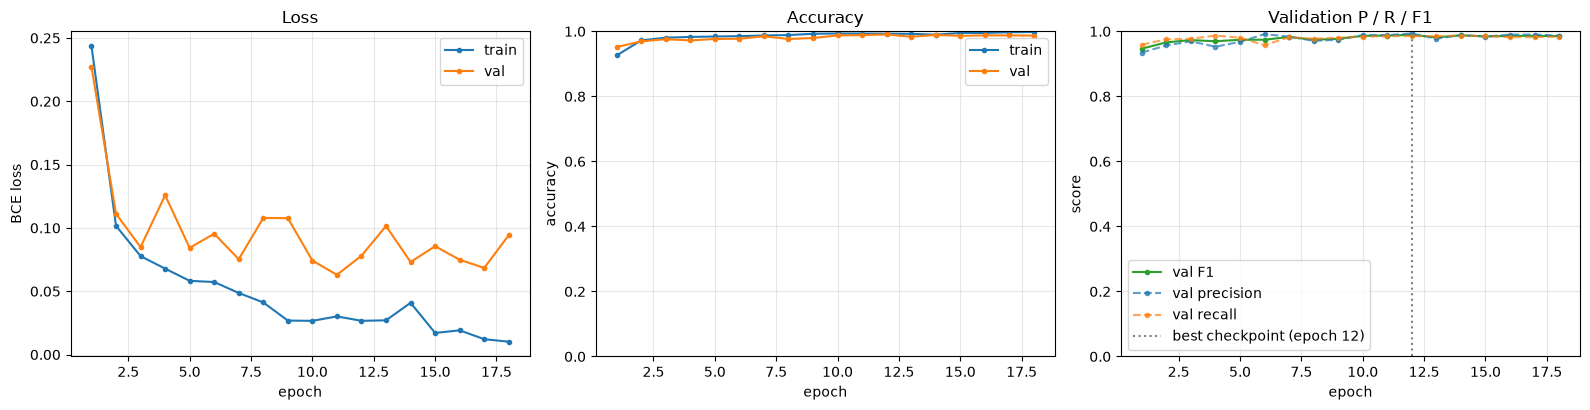

In [10]:
epochs_ran = [h["epoch"] for h in history]
train_loss = [h["train"]["loss"] for h in history]
val_loss = [h["val"]["loss"] for h in history]
train_acc = [h["train"]["acc"] for h in history]
val_acc = [h["val"]["acc"] for h in history]
val_f1 = [h["val"]["f1"] for h in history]
val_prec = [h["val"]["precision"] for h in history]
val_rec = [h["val"]["recall"] for h in history]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

axes[0].plot(epochs_ran, train_loss, label="train", marker="o", ms=3)
axes[0].plot(epochs_ran, val_loss, label="val", marker="o", ms=3)
axes[0].set_title("Loss")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("BCE loss")
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(epochs_ran, train_acc, label="train", marker="o", ms=3)
axes[1].plot(epochs_ran, val_acc, label="val", marker="o", ms=3)
axes[1].set_title("Accuracy")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy")
axes[1].set_ylim(0, 1)
axes[1].legend(); axes[1].grid(alpha=0.3)

axes[2].plot(epochs_ran, val_f1, label="val F1", marker="o", ms=3, color="tab:green")
axes[2].plot(epochs_ran, val_prec, label="val precision", marker="o", ms=3, linestyle="--", alpha=0.7)
axes[2].plot(epochs_ran, val_rec, label="val recall", marker="o", ms=3, linestyle="--", alpha=0.7)
best_epoch = ckpt["epoch"]
axes[2].axvline(best_epoch, color="gray", linestyle=":", label=f"best checkpoint (epoch {best_epoch})")
axes[2].set_title("Validation P / R / F1")
axes[2].set_xlabel("epoch"); axes[2].set_ylabel("score")
axes[2].set_ylim(0, 1)
axes[2].legend(); axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTDIR, "training_curves.png"), dpi=150)
plt.show()

### 9.2 Test-set predictions (for the plots below)

In [11]:
test_probs, test_labels, test_imgs = collect_predictions(model, test_loader, device)
test_preds = (test_probs > 0.5).astype(int)
print(f"Collected {len(test_labels)} test predictions "
      f"({int(test_labels.sum())} FRB / {int((1 - test_labels).sum())} RFI)")

Collected 1362 test predictions (612 FRB / 750 RFI)


### 9.3 Confusion matrix

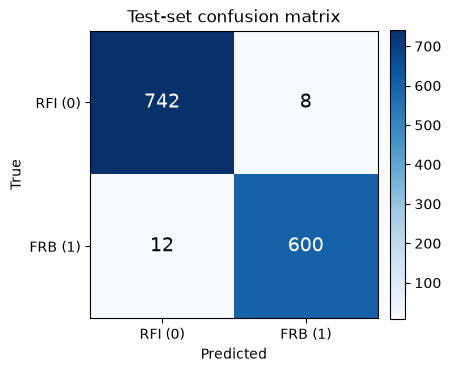

In [12]:
cm = confusion_matrix(test_labels, test_preds, labels=[0, 1])

fig, ax = plt.subplots(figsize=(4.5, 4))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_xticklabels(["RFI (0)", "FRB (1)"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["RFI (0)", "FRB (1)"])
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title("Test-set confusion matrix")
for i in range(2):
    for j in range(2):
        color = "white" if cm[i, j] > cm.max() / 2 else "black"
        ax.text(j, i, str(cm[i, j]), ha="center", va="center", color=color, fontsize=14)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig(os.path.join(OUTDIR, "confusion_matrix.png"), dpi=150)
plt.show()

### 9.4 ROC and precision-recall curves

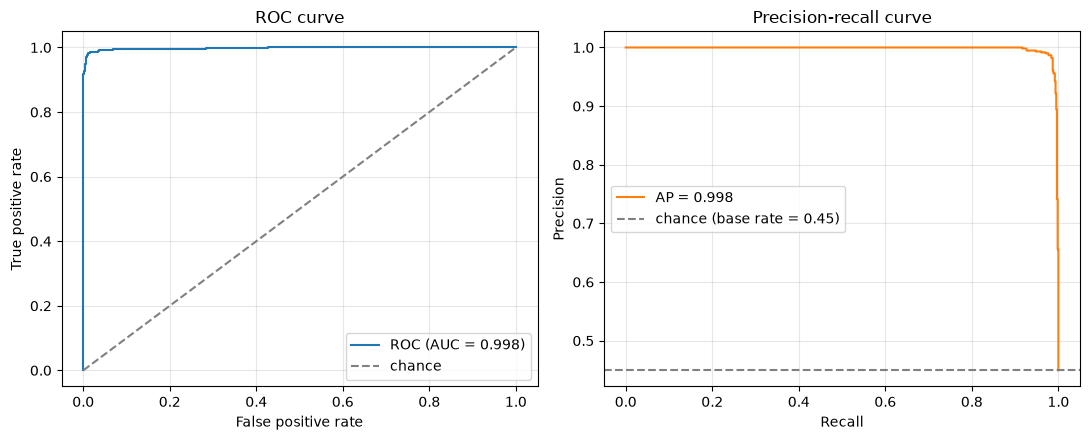

In [13]:
fpr, tpr, _ = roc_curve(test_labels, test_probs)
roc_auc = auc(fpr, tpr)
prec_curve, rec_curve, _ = precision_recall_curve(test_labels, test_probs)
ap = average_precision_score(test_labels, test_probs)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].plot(fpr, tpr, label=f"ROC (AUC = {roc_auc:.3f})", color="tab:blue")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", label="chance")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC curve"); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(rec_curve, prec_curve, label=f"AP = {ap:.3f}", color="tab:orange")
base_rate = test_labels.mean()
axes[1].axhline(base_rate, linestyle="--", color="gray", label=f"chance (base rate = {base_rate:.2f})")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-recall curve"); axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTDIR, "roc_pr_curves.png"), dpi=150)
plt.show()

### 9.5 Classification report

In [14]:
print(classification_report(test_labels, test_preds, target_names=["RFI (0)", "FRB (1)"], digits=3))

              precision    recall  f1-score   support

     RFI (0)      0.984     0.989     0.987       750
     FRB (1)      0.987     0.980     0.984       612

    accuracy                          0.985      1362
   macro avg      0.985     0.985     0.985      1362
weighted avg      0.985     0.985     0.985      1362



### 9.6 Example predictions

A grid of test-set dynamic spectra: correctly classified FRBs and RFI, plus any misclassifications
(false positives / false negatives), so you can visually sanity-check what the model gets wrong.

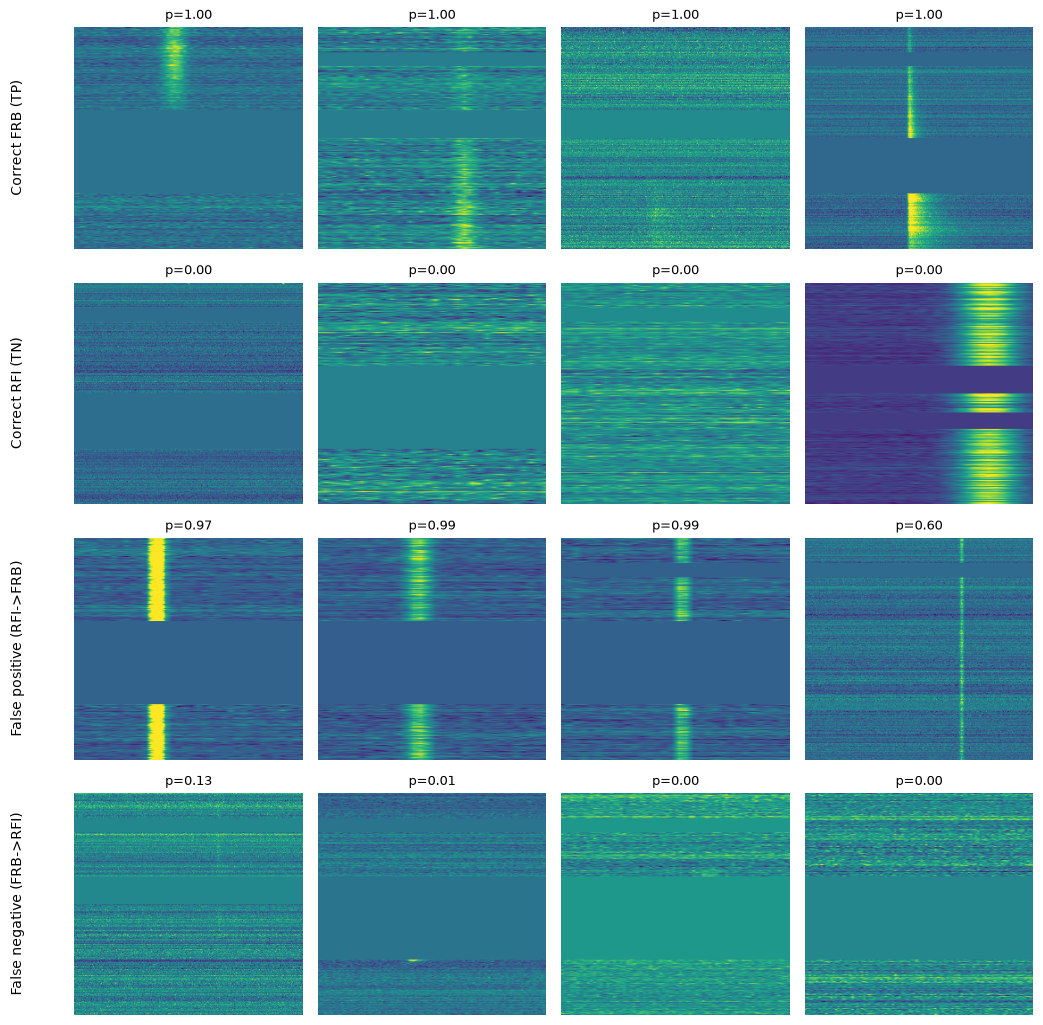

In [15]:
def pick_examples(probs, labels, n=4):
    preds = (probs > 0.5).astype(int)
    idx_tp = np.where((labels == 1) & (preds == 1))[0]
    idx_tn = np.where((labels == 0) & (preds == 0))[0]
    idx_fp = np.where((labels == 0) & (preds == 1))[0]
    idx_fn = np.where((labels == 1) & (preds == 0))[0]
    rng = np.random.default_rng(SEED)
    picks = {}
    for name, idx in [("Correct FRB (TP)", idx_tp), ("Correct RFI (TN)", idx_tn),
                       ("False positive (RFI->FRB)", idx_fp), ("False negative (FRB->RFI)", idx_fn)]:
        picks[name] = rng.choice(idx, size=min(n, len(idx)), replace=False) if len(idx) else np.array([], dtype=int)
    return picks

examples = pick_examples(test_probs, test_labels, n=4)
n_cols = max((len(v) for v in examples.values()), default=1)
n_cols = max(n_cols, 1)
fig, axes = plt.subplots(len(examples), n_cols, figsize=(2.6 * n_cols, 2.6 * len(examples)))
if len(examples) == 1:
    axes = np.array([axes])

for row, (name, idxs) in enumerate(examples.items()):
    for col in range(n_cols):
        ax = axes[row, col] if n_cols > 1 else axes[row]
        ax.axis("off")
        if col < len(idxs):
            i = idxs[col]
            ax.imshow(test_imgs[i, 0], aspect="auto", origin="lower", cmap="viridis")
            ax.set_title(f"p={test_probs[i]:.2f}", fontsize=9)
        if col == 0:
            ax.text(-0.25, 0.5, name, transform=ax.transAxes, rotation=90,
                    va="center", ha="center", fontsize=10)
            ax.axis("off")

plt.tight_layout()
plt.savefig(os.path.join(OUTDIR, "example_predictions.png"), dpi=150)
plt.show()

n_fp, n_fn = len(examples["False positive (RFI->FRB)"]), len(examples["False negative (FRB->RFI)"])
if n_fp == 0 and n_fn == 0:
    print("No misclassifications in the test set at the default 0.5 threshold.")

### 9.7 Summary

Everything from this run is saved under `OUTDIR`:
- `best_model.pt` -- best checkpoint by validation F1
- `history.json` -- per-epoch train/val metrics
- `test_metrics.json` -- final test-set metrics
- `training_curves.png`, `confusion_matrix.png`, `roc_pr_curves.png`, `example_predictions.png`

In [16]:
print(f"acc      = {test_metrics['acc']:.3f}")
print(f"precision= {test_metrics['precision']:.3f}")
print(f"recall   = {test_metrics['recall']:.3f}")
print(f"f1       = {test_metrics['f1']:.3f}")
print(f"ROC AUC  = {roc_auc:.3f}")
print(f"PR AUC   = {ap:.3f}")
print(f"best checkpoint: epoch {ckpt['epoch']}  (saved to {best_path})")

acc      = 0.985
precision= 0.987
recall   = 0.980
f1       = 0.984
ROC AUC  = 0.998
PR AUC   = 0.998
best checkpoint: epoch 12  (saved to runs/exp3/best_model.pt)
